# Taller 1 - Teoría de Aprendizaje de Máquina (2026-2)
## Solución computacional para Google Colab

Este cuaderno complementa el informe en LaTeX. Contiene las verificaciones numéricas y los experimentos de los incisos que requieren Python.

**Cómo usarlo en Colab:** sube este archivo a Google Drive y ábrelo con Google Colaboratory. Ejecuta las celdas en orden (`Entorno de ejecución > Ejecutar todas`). Las bibliotecas utilizadas (`numpy`, `matplotlib`, `pandas` y `scikit-learn`) normalmente ya están disponibles en Colab.

**Reproducibilidad:** se conservan los valores `random_state=42` del enunciado y se fija también la semilla de NumPy.

In [1]:
# 0. Importaciones y configuración general
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

np.random.seed(42)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


---
# Punto 1. Clasificación lineal y perceptrón

## Inciso 1.1. Frontera de decisión

El clasificador está definido por

\[
f(\mathbf{x})=\mathbf{w}^T\mathbf{x}+b=x_1+2x_2-3.
\]

La frontera es \(x_1+2x_2-3=0\), o equivalentemente \(x_2=(3-x_1)/2\). Se predice \(+1\) cuando \(f(\mathbf{x})>0\) y \(-1\) cuando \(f(\mathbf{x})\leq 0\).

,Observación,Coordenadas,f(x),Clase predicha
0,x1,"(0.0, 0.0)",-3.0,-1
1,x2,"(1.0, 0.0)",-2.0,-1
2,x3,"(2.0, 1.0)",1.0,1
3,x4,"(3.0, 1.0)",2.0,1


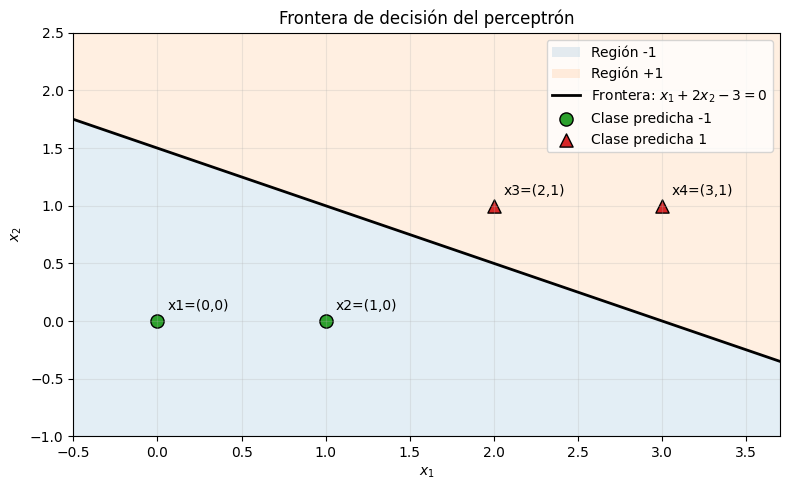

In [2]:
# Inciso 1.1: clasificar los cuatro puntos y dibujar la frontera
w = np.array([1.0, 2.0])
b = -3.0
X_points = np.array([[0, 0], [1, 0], [2, 1], [3, 1]], dtype=float)

scores = X_points @ w + b
predictions = np.where(scores > 0, 1, -1)

results_perceptron = pd.DataFrame({
    "Observación": ["x1", "x2", "x3", "x4"],
    "Coordenadas": [tuple(p) for p in X_points],
    "f(x)": scores,
    "Clase predicha": predictions,
})
display(results_perceptron)

x1_line = np.linspace(-0.5, 3.7, 300)
x2_line = (3 - x1_line) / 2

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(x1_line, -1.2, x2_line, alpha=0.12, label="Región -1")
ax.fill_between(x1_line, x2_line, 2.5, alpha=0.12, label="Región +1")
ax.plot(x1_line, x2_line, color="black", linewidth=2,
        label=r"Frontera: $x_1+2x_2-3=0$")

for cls, marker in [(-1, "o"), (1, "^")]:
    mask = predictions == cls
    ax.scatter(X_points[mask, 0], X_points[mask, 1], s=90,
               marker=marker, edgecolor="black", label=f"Clase predicha {cls}")

for i, (xp, yp) in enumerate(X_points, start=1):
    ax.annotate(f"x{i}=({xp:.0f},{yp:.0f})", (xp, yp),
                xytext=(7, 8), textcoords="offset points")

ax.set(xlim=(-0.5, 3.7), ylim=(-1.0, 2.5), xlabel=r"$x_1$",
       ylabel=r"$x_2$", title="Frontera de decisión del perceptrón")
ax.legend()
plt.tight_layout()
plt.show()

## Inciso 1.2. Verificación numérica de la propiedad del margen

La demostración algebraica se encuentra en el informe LaTeX. La identidad que se verifica es

\[
m_{i,\mathrm{nuevo}}=m_i+\eta(\|\mathbf{x}_i\|_2^2+1).
\]

El aumento es estrictamente positivo porque \(\eta>0\) y \(\|\mathbf{x}_i\|_2^2+1>0\).

In [3]:
# Inciso 1.2: verificación computacional con una observación de ejemplo
eta = 0.5
x_i = np.array([2.0, 1.0])
y_i = 1.0
w_old = np.array([0.0, 0.0])
b_old = 0.0

margin_old = y_i * (w_old @ x_i + b_old)
w_new = w_old + eta * y_i * x_i
b_new = b_old + eta * y_i
margin_new_direct = y_i * (w_new @ x_i + b_new)
margin_new_formula = margin_old + eta * (np.linalg.norm(x_i)**2 + 1)

print(f"Margen inicial: {margin_old:.4f}")
print(f"Margen nuevo (parámetros): {margin_new_direct:.4f}")
print(f"Margen nuevo (fórmula): {margin_new_formula:.4f}")
print("¿Coinciden?", np.isclose(margin_new_direct, margin_new_formula))

Margen inicial: 0.0000
Margen nuevo (parámetros): 3.0000
Margen nuevo (fórmula): 3.0000
¿Coinciden? True


## Inciso 1.3. Ejercicio numérico

Datos: \(\mathbf{w}= [0,0]^T\), \(b=0\), \(\eta=0.5\), \(\mathbf{x}=[2,1]^T\) y \(y=+1\). Como \(f(\mathbf{x})=0\), la regla predice \(-1\); por tanto, la observación está mal clasificada y se actualizan los parámetros.

In [4]:
# Inciso 1.3: actualización completa del perceptrón
w = np.array([0.0, 0.0])
b = 0.0
eta = 0.5
x = np.array([2.0, 1.0])
y_real = 1

f_before = w @ x + b
y_pred = 1 if f_before > 0 else -1
margin_before = y_real * f_before

print("Función de decisión inicial:", f_before)
print("Predicción inicial:", y_pred)
print("Etiqueta real:", y_real)

if y_pred != y_real:
    w_new = w + eta * y_real * x
    b_new = b + eta * y_real
else:
    w_new, b_new = w.copy(), b

margin_after = y_real * (w_new @ x + b_new)
print("\nPesos nuevos:", w_new)
print("Sesgo nuevo:", b_new)
print("Margen inicial:", margin_before)
print("Margen nuevo:", margin_after)

Función de decisión inicial: 0.0
Predicción inicial: -1
Etiqueta real: 1

Pesos nuevos: [1.  0.5]
Sesgo nuevo: 0.5
Margen inicial: 0.0
Margen nuevo: 3.0


---
# Punto 2. Clasificación por k-NN

## Inciso 2.1. Cálculo manual de las distancias

La observación nueva es \(q=(1,1)\). La tabla del PDF original muestra \(x_5=(1.1,1.1)\), clase B. Se calcula la distancia euclidiana a cada observación y se ordenan los vecinos.

In [5]:
# Inciso 2.1: distancias y votación manual verificadas con Python
q = np.array([1.0, 1.0])
X_manual = np.array([
    [0.0, 0.0],
    [1.0, 0.0],
    [3.0, 1.0],
    [0.0, 3.0],
    [1.1, 1.1],
])
classes_manual = np.array(["A", "A", "B", "B", "B"])

# Se calcula una distancia por fila.
distances = np.linalg.norm(X_manual - q, axis=1)
manual_df = pd.DataFrame({
    "Observación": [f"x{i}" for i in range(1, 6)],
    "Coordenadas": [tuple(p) for p in X_manual],
    "Clase": classes_manual,
    "Distancia": distances,
}).sort_values("Distancia").reset_index(drop=True)
display(manual_df)

for k in [1, 3, 5]:
    selected = manual_df.head(k)
    votes = selected["Clase"].value_counts()
    predicted_class = votes.index[0]
    print(f"k={k}: votos={votes.to_dict()} -> clase asignada={predicted_class}")

,Observación,Coordenadas,Clase,Distancia
0,x5,"(1.1, 1.1)",B,0.141421
1,x2,"(1.0, 0.0)",A,1.000000
2,x1,"(0.0, 0.0)",A,1.414214
3,x3,"(3.0, 1.0)",B,2.000000
4,x4,"(0.0, 3.0)",B,2.236068


k=1: votos={'B': 1} -> clase asignada=B
k=3: votos={'A': 2, 'B': 1} -> clase asignada=A
k=5: votos={'B': 3, 'A': 2} -> clase asignada=B


## Inciso 2.2. Generación, división y entrenamiento de los modelos

Se generan 300 observaciones con `make_moons(noise=0.20, random_state=42)`. Se realiza una división estratificada de 70 % para entrenamiento y 30 % para prueba. Se entrenan modelos con \(k\in\{1,5,15\}\).

In [6]:
# Inciso 2.2, paso 1: generar y dividir los datos
X, y = make_moons(n_samples=300, noise=0.20, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("Datos completos:", X.shape)
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Clases en entrenamiento:", np.bincount(y_train))
print("Clases en prueba:", np.bincount(y_test))

Datos completos: (300, 2)
Entrenamiento: (210, 2)
Prueba: (90, 2)
Clases en entrenamiento: [105 105]
Clases en prueba: [45 45]


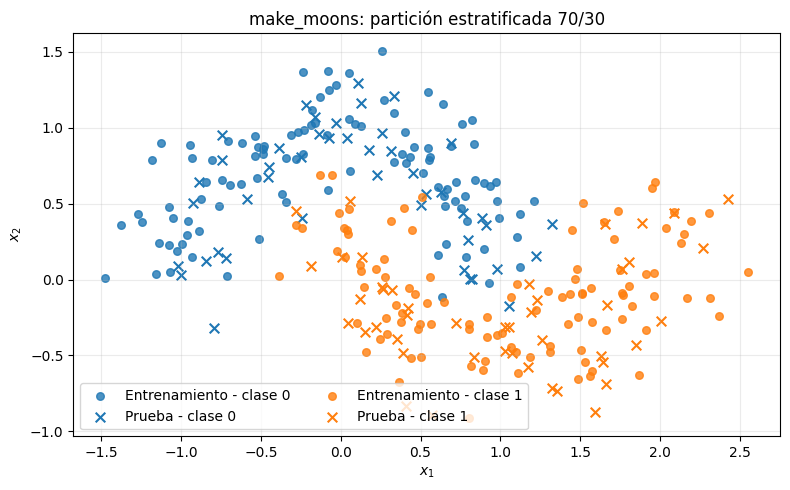

In [7]:
# Inciso 2.2, paso 2: visualizar entrenamiento y prueba
fig, ax = plt.subplots(figsize=(8, 5))
colors = {0: "tab:blue", 1: "tab:orange"}

for cls in [0, 1]:
    train_mask = y_train == cls
    test_mask = y_test == cls
    ax.scatter(X_train[train_mask, 0], X_train[train_mask, 1],
               color=colors[cls], s=30, marker="o", alpha=0.8,
               label=f"Entrenamiento - clase {cls}")
    ax.scatter(X_test[test_mask, 0], X_test[test_mask, 1],
               color=colors[cls], s=48, marker="x",
               label=f"Prueba - clase {cls}")

ax.set_title("make_moons: partición estratificada 70/30")
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

In [8]:
# Inciso 2.2, paso 3: entrenar y comparar k = 1, 5 y 15
k_values = [1, 5, 15]
models = {}
rows = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    models[k] = model

    acc_train = accuracy_score(y_train, model.predict(X_train))
    acc_test = accuracy_score(y_test, model.predict(X_test))

    rows.append({
        "k": k,
        "Accuracy entrenamiento": acc_train,
        "Accuracy prueba": acc_test,
    })

results_knn = pd.DataFrame(rows)
display(results_knn.style.format({
    "Accuracy entrenamiento": "{:.4f}",
    "Accuracy prueba": "{:.4f}",
}))

,k,Accuracy entrenamiento,Accuracy prueba
0,1,1.0000,0.9333
1,5,0.9571,0.9556
2,15,0.9571,0.9333


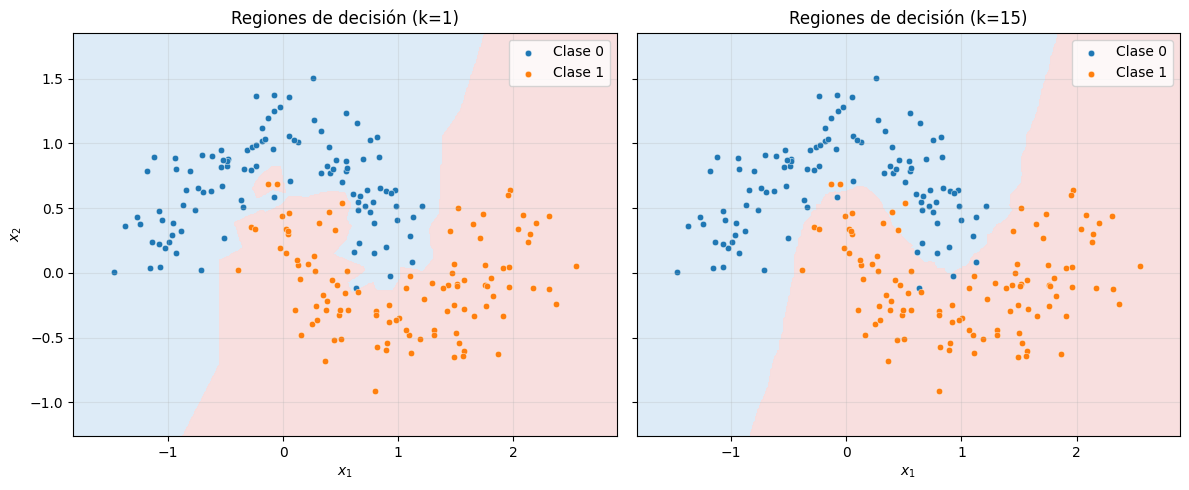

In [9]:
# Inciso 2.2, paso 4: regiones de decisión para k=1 y k=15
x_min, x_max = X[:, 0].min() - 0.35, X[:, 0].max() + 0.35
y_min, y_max = X[:, 1].min() - 0.35, X[:, 1].max() + 0.35
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 420),
    np.linspace(y_min, y_max, 320),
)
grid = np.c_[xx.ravel(), yy.ravel()]
light_cmap = ListedColormap(["#dceaf7", "#f8dede"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, k in zip(axes, [1, 15]):
    model = models[k]
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=light_cmap, alpha=0.95, levels=[-0.5, 0.5, 1.5])
    for cls in [0, 1]:
        mask = y_train == cls
        ax.scatter(X_train[mask, 0], X_train[mask, 1],
                   color=colors[cls], s=22, edgecolor="white",
                   linewidth=0.3, label=f"Clase {cls}")
    ax.set_title(f"Regiones de decisión (k={k})")
    ax.set_xlabel(r"$x_1$")
    ax.legend()
axes[0].set_ylabel(r"$x_2$")
plt.tight_layout()
plt.show()

## Inciso 2.3. Interpretación

- **k pequeño:** la decisión depende de pocos vecinos. Para \(k=1\), el accuracy de entrenamiento llega a 100 % porque cada punto de entrenamiento es su propio vecino más cercano. La frontera puede ser irregular y sensible al ruido (riesgo de sobreajuste).
- **k grande:** se consideran más vecinos, por lo que la frontera tiende a suavizarse. Si el valor es excesivo, se puede perder estructura local (riesgo de subajuste).

En la partición solicitada, \(k=5\) presenta el mayor accuracy de prueba: aproximadamente 95.56 %. La diferencia entre entrenamiento y prueba también es pequeña. Sin embargo, el valor de \(k\) debe seleccionarse formalmente mediante validación cruzada aplicada solo al conjunto de entrenamiento. El conjunto de prueba se reserva para la evaluación final.

### Validación cruzada opcional (complemento metodológico)

El siguiente bloque no sustituye la comparación obligatoria de \(k=1,5,15\). Muestra cómo seleccionar el hiperparámetro utilizando únicamente los datos de entrenamiento; luego se puede estimar una vez el rendimiento del modelo escogido en el conjunto de prueba.

In [10]:
# Complemento: selección de k mediante validación cruzada en entrenamiento
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={"n_neighbors": list(range(1, 26))},
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Mejor k según validación cruzada:", search.best_params_["n_neighbors"])
print(f"Accuracy medio de validación: {search.best_score_:.4f}")
print(f"Accuracy en prueba para el modelo elegido: {search.score(X_test, y_test):.4f}")
print("Nota: el conjunto de prueba no participó en la selección del hiperparámetro.")

Mejor k según validación cruzada: 11
Accuracy medio de validación: 0.9619
Accuracy en prueba para el modelo elegido: 0.9667
Nota: el conjunto de prueba no participó en la selección del hiperparámetro.


---
# Punto 3. Evaluación de un clasificador binario

## Inciso 3.1. Matriz de confusión

Se toma la clase 1 como positiva. Las filas de `confusion_matrix` son las clases reales y las columnas las clases predichas, con el orden de etiquetas `[0, 1]`.

\[
\begin{bmatrix}TN & FP\\ FN & TP\end{bmatrix}
=
\begin{bmatrix}3 & 1\\2 & 4\end{bmatrix}.
\]

Matriz de confusión (filas=real, columnas=predicha):
[[3 1]
 [2 4]]
TN=3, FP=1, FN=2, TP=4


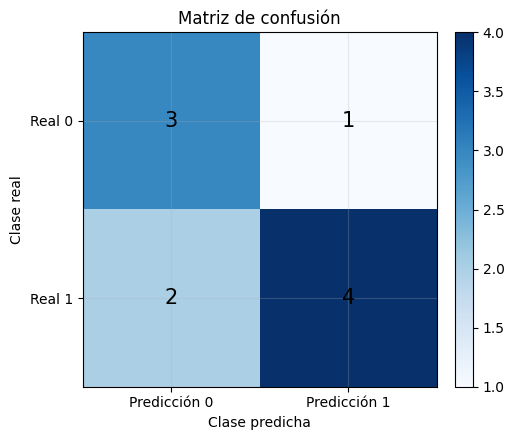

In [11]:
# Incisos 3.1 y 3.2: matriz de confusión y conteos

y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

print("Matriz de confusión (filas=real, columnas=predicha):")
print(cm)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["Predicción 0", "Predicción 1"])
ax.set_yticks([0, 1], labels=["Real 0", "Real 1"])
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", fontsize=15)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [12]:
# Inciso 3.2: cálculo manual de las métricas
accuracy_manual = (TP + TN) / (TP + TN + FP + FN)
precision_manual = TP / (TP + FP)
recall_manual = TP / (TP + FN)
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual)

manual_metrics = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1"],
    "Resultado": [accuracy_manual, precision_manual, recall_manual, f1_manual],
})
display(manual_metrics.style.format({"Resultado": "{:.6f}"}))

,Métrica,Resultado
0,Accuracy,0.700000
1,Precision,0.800000
2,Recall,0.666667
3,F1,0.727273


## Inciso 3.3. Verificación con scikit-learn

Se comparan los cálculos manuales con `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score` y `f1_score`.

In [13]:
# Inciso 3.3: verificación con las funciones solicitadas
cm_sklearn = confusion_matrix(y_true, y_pred, labels=[0, 1])
accuracy_sklearn = accuracy_score(y_true, y_pred)
precision_sklearn = precision_score(y_true, y_pred, pos_label=1)
recall_sklearn = recall_score(y_true, y_pred, pos_label=1)
f1_sklearn = f1_score(y_true, y_pred, pos_label=1)

print("Matriz de confusión:")
print(cm_sklearn)
print(f"Accuracy:  {accuracy_sklearn:.6f}")
print(f"Precision: {precision_sklearn:.6f}")
print(f"Recall:    {recall_sklearn:.6f}")
print(f"F1:        {f1_sklearn:.6f}")

assert np.array_equal(cm, cm_sklearn)
assert np.isclose(accuracy_manual, accuracy_sklearn)
assert np.isclose(precision_manual, precision_sklearn)
assert np.isclose(recall_manual, recall_sklearn)
assert np.isclose(f1_manual, f1_sklearn)
print("\nVerificación correcta: los resultados manuales coinciden con scikit-learn.")

Matriz de confusión:
[[3 1]
 [2 4]]
Accuracy:  0.700000
Precision: 0.800000
Recall:    0.666667
F1:        0.727273

Verificación correcta: los resultados manuales coinciden con scikit-learn.


### Dos situaciones en las que accuracy puede ser engañosa

1. **Clases desbalanceadas:** si existen 990 transacciones normales y 10 fraudulentas, un modelo que siempre predice “normal” obtiene 99 % de accuracy, pero no detecta ningún fraude.
2. **Costos de error diferentes:** en una aplicación médica, un falso negativo puede ser mucho más costoso que un falso positivo. Accuracy no diferencia el impacto de esos errores, por lo que conviene revisar recall, precision y la matriz de confusión.

In [14]:
# Ejemplo reproducible de clases desbalanceadas
# 990 normales (0) y 10 fraudulentas (1); el modelo predice todo como normal.
y_imbalanced = np.array([0] * 990 + [1] * 10)
y_always_normal = np.zeros_like(y_imbalanced)

print("Accuracy del clasificador trivial:", accuracy_score(y_imbalanced, y_always_normal))
print("Recall de la clase fraude:", recall_score(y_imbalanced, y_always_normal, pos_label=1, zero_division=0))
print("Matriz de confusión:")
print(confusion_matrix(y_imbalanced, y_always_normal, labels=[0, 1]))

Accuracy del clasificador trivial: 0.99
Recall de la clase fraude: 0.0
Matriz de confusión:
[[990   0]
 [ 10   0]]


---
# Conclusiones

- El perceptrón forma una frontera lineal y actualiza sus parámetros cuando una observación está mal clasificada. La actualización incrementa el margen de esa observación.
- k-NN clasifica mediante distancias y votación. En el experimento solicitado, \(k=5\) obtuvo el mayor accuracy de prueba (95.56 %).
- Accuracy, precision, recall y F1 describen aspectos distintos del desempeño; deben interpretarse de acuerdo con las consecuencias de los errores.
- La semilla y la partición estratificada permiten reproducir el experimento. La validación se utiliza para seleccionar hiperparámetros y el conjunto de prueba se mantiene reservado para la evaluación final.